### We'll practice using the white wine data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df_white = pd.read_csv(
  "data/winequality-white.csv",
  sep=";"
)
df_white.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [3]:
## Statistical Overview
df_white.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [4]:
## Rename the columns to snake_case
df_white.columns = df_white.columns.str.replace(" ", "_")
df_white.columns

Index(['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
       'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

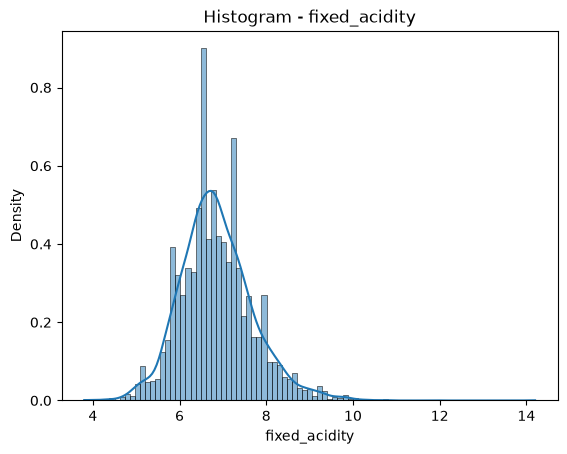

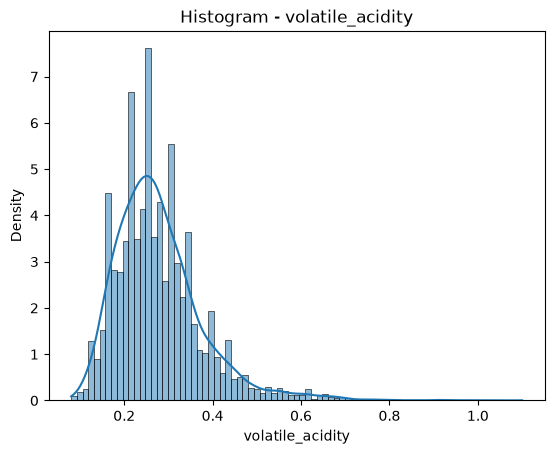

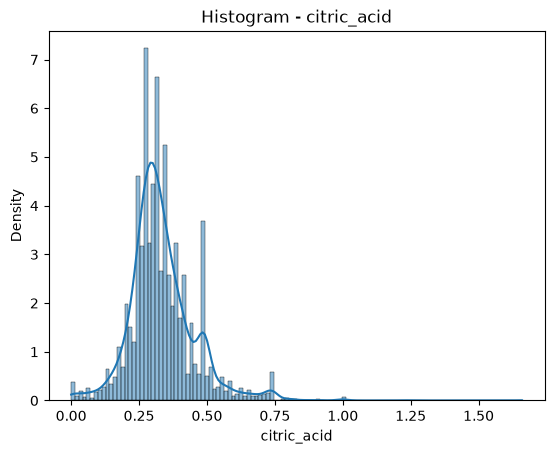

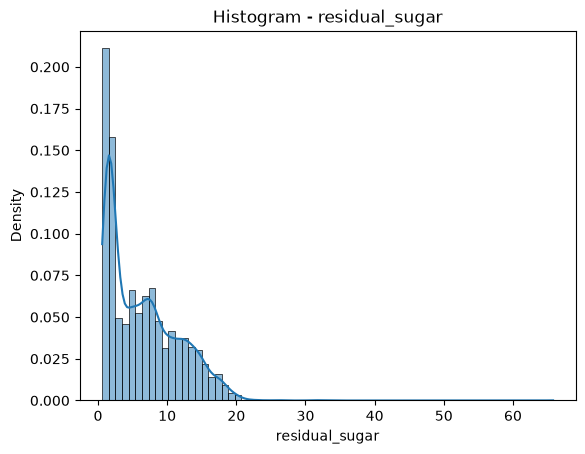

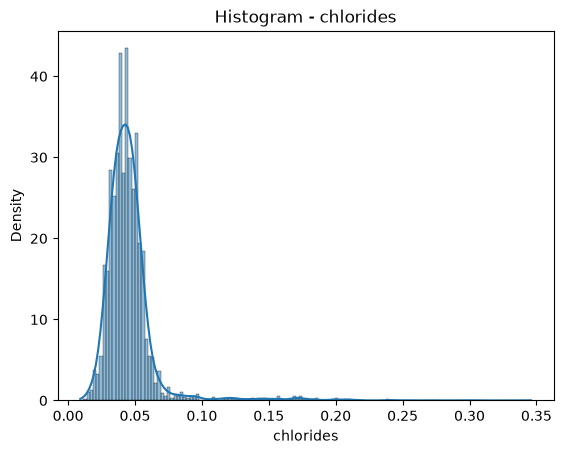

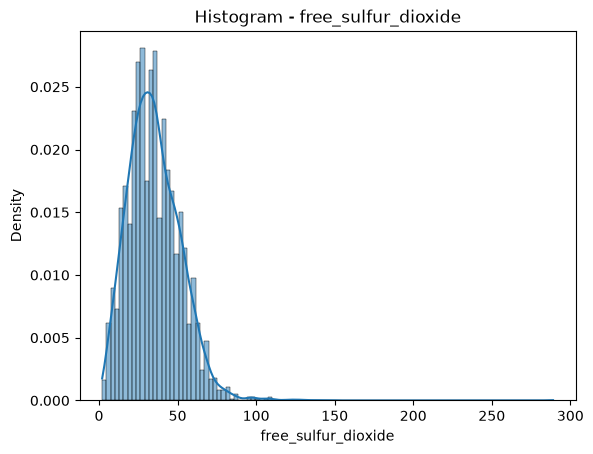

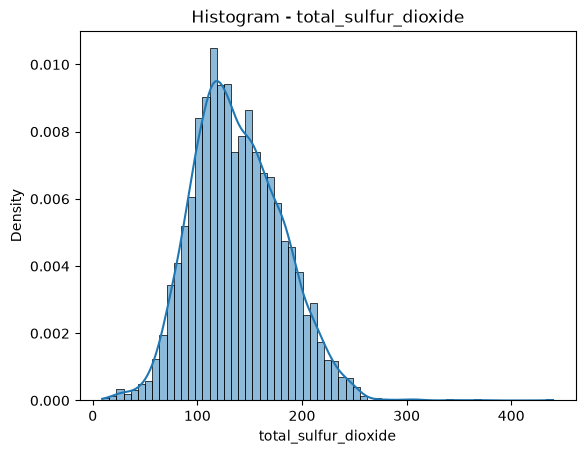

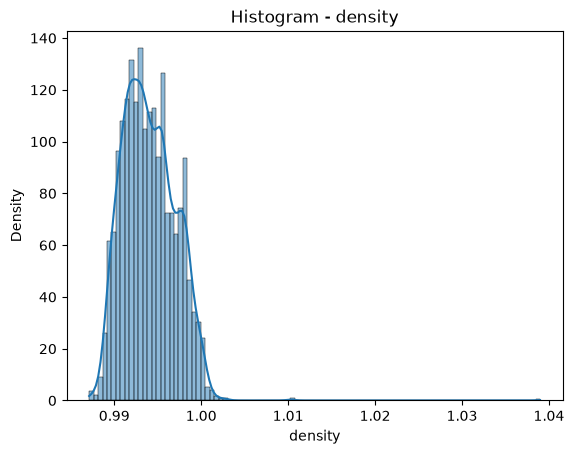

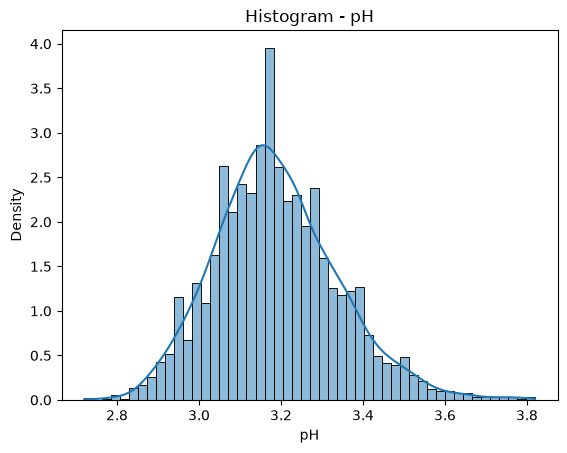

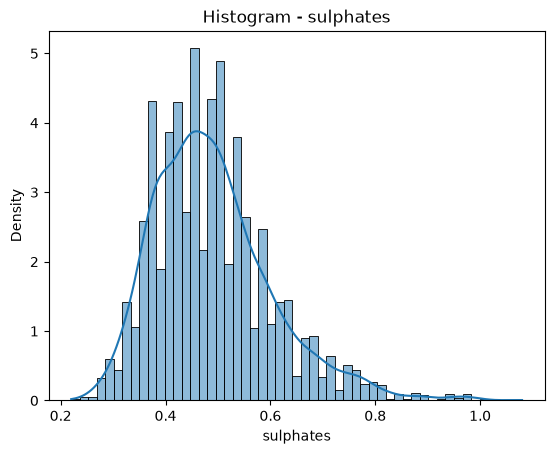

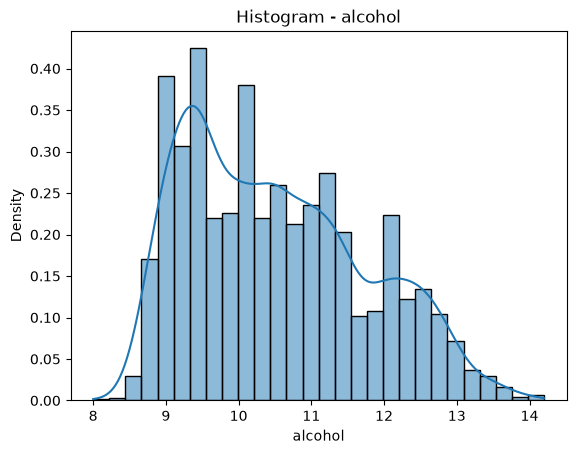

In [8]:
## Plot the histograms with KDE to see data distributions - They look similar as the red wine data
for cols in df_white.columns[:-1]:
  sns.histplot(df_white[cols], kde=True, stat="density")
  plt.title(f"Histogram - {cols}")
  plt.show()


<Axes: >

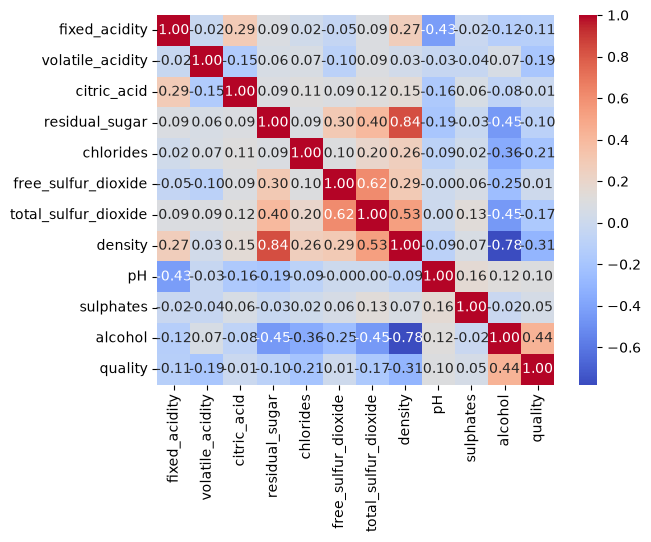

In [ ]:
## We observe the correlation between features using pearson correlation coefficients
## Correlation also looks similar
pearson_corr = df_white.corr()
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", fmt=".2f")

<Axes: xlabel='residual_sugar', ylabel='density'>

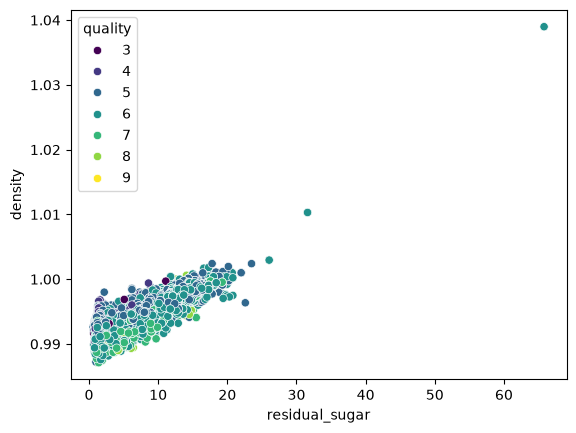

In [13]:
## We can try to observe the scatter plot between residual sugar and density (strong correlation)
sns.scatterplot(
  x=df_white['residual_sugar'],
  y=df_white['density'],
  data=df_white,
  hue="quality",
  palette="viridis"
)

In [14]:
## We do feature scaling -  as we will use KMeans, which is susceptible with scaling
from sklearn.preprocessing import StandardScaler
X = df_white.drop(columns=["quality"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [17]:
## We do PCAs first and observe the variance retained
from sklearn.decomposition import PCA
for n in range(2, 12):
  pca = PCA(n_components=n)
  X_pca = pca.fit_transform(X_scaled)

  variance = pca.explained_variance_ratio_.sum().round(2)

  print(
    f"n = {n} | "
    f"Variance retained: {variance}"
  )

n = 2 | Variance retained: 0.44
n = 3 | Variance retained: 0.55
n = 4 | Variance retained: 0.64
n = 5 | Variance retained: 0.73
n = 6 | Variance retained: 0.81
n = 7 | Variance retained: 0.88
n = 8 | Variance retained: 0.93
n = 9 | Variance retained: 0.97
n = 10 | Variance retained: 1.0
n = 11 | Variance retained: 1.0


K: 2 | Silhouette Score: 0.21
K: 3 | Silhouette Score: 0.14
K: 4 | Silhouette Score: 0.16
K: 5 | Silhouette Score: 0.14
K: 6 | Silhouette Score: 0.15
K: 7 | Silhouette Score: 0.13
K: 8 | Silhouette Score: 0.12
K: 9 | Silhouette Score: 0.13


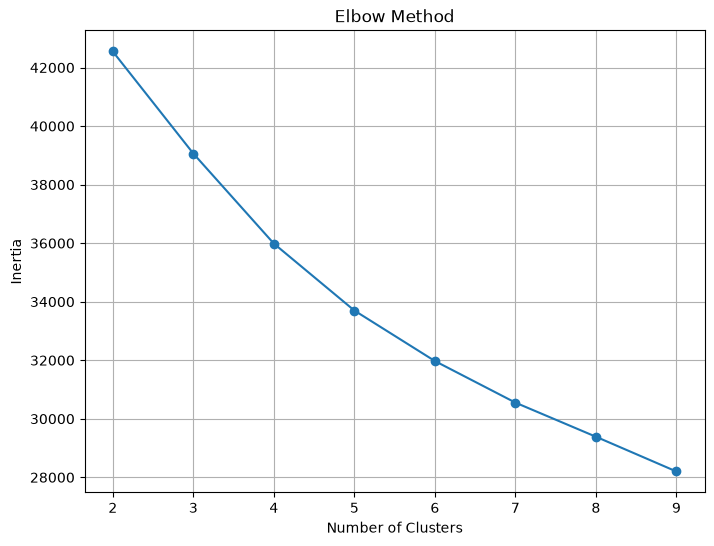

In [ ]:
## We can start implementing KMeans using all features then later compared with different PCAs
## Again, we can see using all features, using only 2 clusters resulting the highes silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []
inertia = []
for k in range(2, 10):
  kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
  )

  labels = kmeans.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, labels)
  silhouette_scores.append(score)
  inertia.append(kmeans.inertia_)

  print(
    f"K: {k} | Silhouette Score: {score:.2f}"
  )

## Also plot the elbow
plt.figure(figsize=(8, 6))
plt.plot(range(2, 10), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 10))
plt.title("Elbow Method")
plt.grid(True)
plt.show()

In [ ]:
## We can try and observe model using 5 PCAs across different clusters
## Use 5 PCAs (it retains around 73% Variance)
pca_5d = PCA(n_components=5)
X_pca_5d = pca_5d.fit_transform(X_scaled)

K: 2 | Silhouette score (5PCAs): 0.280889
K: 3 | Silhouette score (5PCAs): 0.210131
K: 4 | Silhouette score (5PCAs): 0.213896
K: 5 | Silhouette score (5PCAs): 0.201995
K: 6 | Silhouette score (5PCAs): 0.200871
K: 7 | Silhouette score (5PCAs): 0.172270
K: 8 | Silhouette score (5PCAs): 0.166876
K: 9 | Silhouette score (5PCAs): 0.162589


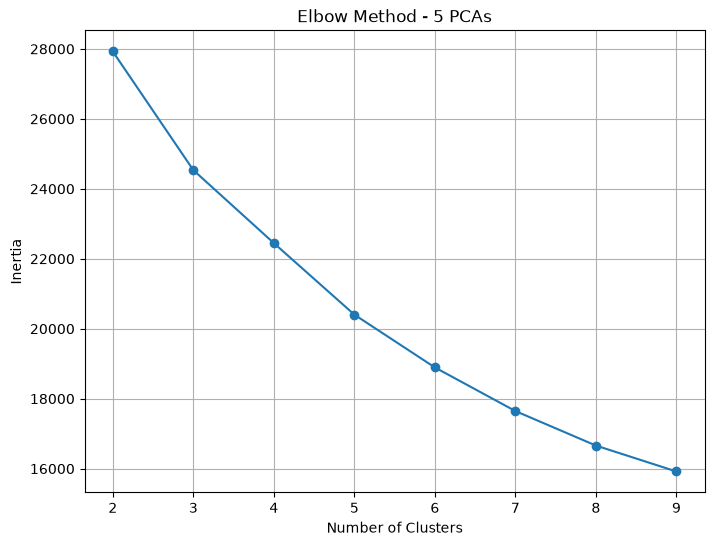

In [ ]:
## Now we test it on our KMean across different clusters
silhouette_scores_5d = []
inertia_5d = []
for k in range(2, 10):
  kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
  )
  labels = kmeans.fit_predict(X_pca_5d, labels)
  score = silhouette_score(X_pca_5d, labels)

  silhouette_scores_5d.append(score)
  inertia_5d.append(kmeans.inertia_)

  print(
    f"K: {k} | Silhouette score (5PCAs): {score:2f}"
  )

## Plot the elbow
plt.figure(figsize=(8, 6))
plt.plot(range(2, 10), inertia_5d, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 10))
plt.title("Elbow Method - 5 PCAs")
plt.grid(True)
plt.show()

In [28]:
## Furthermore, we can actually see the number of red wines for each cluster
## This one we use 2, since 2 clusters resulting in highest silhouette scores
kmeans_5d = KMeans(
  n_clusters=2,
  random_state=42,
  n_init=10
)
labels_5d = kmeans_5d.fit_predict(X_pca_5d)
print(pd.Series(labels_5d).value_counts().sort_index())

0    1972
1    2926
Name: count, dtype: int64


In [ ]:
## Next, we can calculate the average values of the chemicals features for each cluster (0 and 1)
## Create copy of the dataset and add "cluster" columns
df_clusters = df_white.copy()
df_clusters["cluster"] = labels_5d

In [30]:
## Count the average
cluster_means = df_clusters.groupby("cluster").mean(numeric_only=True)
print(cluster_means)

         fixed_acidity  volatile_acidity  citric_acid  residual_sugar  \
cluster                                                                 
0             7.012931          0.282807     0.361998       10.629970   
1             6.748206          0.275164     0.315451        3.534809   

         chlorides  free_sulfur_dioxide  total_sulfur_dioxide   density  \
cluster                                                                   
0         0.054296            45.342292            170.989097  0.996843   
1         0.040028            28.545455            116.370472  0.992130   

               pH  sulphates    alcohol   quality  
cluster                                            
0        3.157855   0.496303   9.543458  5.601420  
1        3.208763   0.485496  11.168551  6.064252  


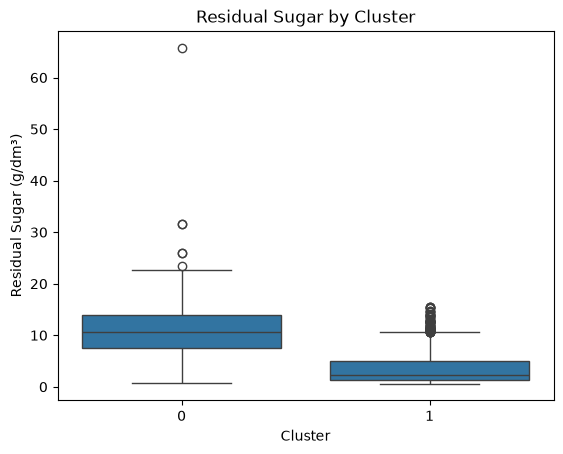

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,1972.0,10.629970,4.722069,0.8,7.6,10.7,13.9,65.8
1,2926.0,3.534809,2.787362,0.6,1.4,2.2,5.1,15.5


In [32]:
sns.boxplot(data=df_clusters, x='cluster', y='residual_sugar')

plt.title('Residual Sugar by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Residual Sugar (g/dm³)')
plt.show()
df_clusters.groupby('cluster')['residual_sugar'].describe()